<a href="https://colab.research.google.com/github/kaixing189/MSSP607/blob/main/Assignments/CaseStudy2_InternetSales_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MSSP607 Case Study Report Assignment 2


## 1. Setup and Load Data

The course CSV uses Windows-1252 encoding. The code checks common Colab/GitHub locations so the notebook can run after the data file is saved to `MSSP607/data/InternetSales.csv`.

In [5]:
from pathlib import Path
import subprocess

REPO_DIR = Path("/content/MSSP607")

# Clone the repository if it is not already in Colab
if not REPO_DIR.exists():
    subprocess.run(
        ["git", "clone", "https://github.com/kaixing189/MSSP607.git", str(REPO_DIR)],
        check=True
    )
    print("Repository cloned successfully.")
else:
    subprocess.run(
        ["git", "-C", str(REPO_DIR), "pull"],
        check=True
    )
    print("Repository already exists. Latest files pulled.")

DATA_PATH = REPO_DIR / "data" / "InternetSales.csv"

print("Data file:", DATA_PATH)
print("File exists:", DATA_PATH.exists())

Repository already exists. Latest files pulled.
Data file: /content/MSSP607/data/InternetSales.csv
File exists: True


In [6]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
from scipy import stats

candidates = [
    Path('/content/MSSP607/data/InternetSales.csv'),
    Path('/content/InternetSales.csv'),
    Path('InternetSales.csv'),
    Path('/mnt/data/InternetSales.csv')
]
DATA_PATH = next((p for p in candidates if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError('InternetSales.csv was not found. Upload it or place it in MSSP607/data/.')

sales = pd.read_csv(DATA_PATH, encoding='cp1252', low_memory=False)
sales['OrderDate'] = pd.to_datetime(sales['OrderDate'])
sales['Year'] = sales['OrderDate'].dt.year
print('Data path:', DATA_PATH)
print('Shape:', sales.shape)
sales.head()

Data path: /content/MSSP607/data/InternetSales.csv
Shape: (60398, 61)


,ID,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,...,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate,Year
0,0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1912.1544,3399.99,271.9992,84.9998,NaN,NaN,2011-01-19,1/31/2011,1/26/2011,2011
1,1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1265.6195,2319.99,185.5992,57.9998,NaN,NaN,2013-01-18,1/30/2013,1/25/2013,2013
2,2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,8.2205,21.98,1.7584,0.5495,NaN,NaN,2013-01-18,1/30/2013,1/25/2013,2013
3,3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1481.9379,2384.07,190.7256,59.6018,NaN,NaN,2013-05-03,5/15/2013,5/10/2013,2013
4,4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,10.8423,28.99,2.3192,0.7248,NaN,NaN,2013-05-03,5/15/2013,5/10/2013,2013


## 2. Product Category Preparation


In [7]:
def assign_category(name):
    name = str(name)
    if re.match(r'^(Mountain|Road|Touring)-\d', name):
        return 'Bikes'
    if re.search(r'Cap|Jersey|Gloves|Vest|Shorts|Socks|Tights', name, flags=re.I):
        return 'Clothing'
    return 'Accessories'

sales['ProductCategory'] = sales['EnglishProductName'].map(assign_category)
sales['ProductCategory'].value_counts()

,count
ProductCategory,
Accessories,36092
Bikes,15205
Clothing,9101


## Question 1. Internet Sales by Year for Each Country Region

2010 contains only the last few days of December, and 2014 contains only January. They are included in the required table, but they should not be interpreted as full-year performance. The figure uses the complete years 2011-2013 for a fair trend comparison.

In [8]:
year_country = sales.pivot_table(
    index='Year',
    columns='EnglishCountryRegionName',
    values='SalesAmount',
    aggfunc='sum',
    fill_value=0
).round(2)
year_country

EnglishCountryRegionName,Australia,Canada,France,Germany,United Kingdom,United States
Year,,,,,,
2010,20909.78,3578.27,3399.99,0.00,699.10,14833.90
2011,2563732.25,571571.80,410845.33,520500.16,550591.22,2458285.17
2012,2128407.46,307604.52,648065.54,608657.98,712700.96,1437048.73
2013,4339443.38,1085632.65,1578511.80,1761876.36,2124007.29,5462078.86
2014,8507.72,9457.62,3195.06,3277.83,3713.64,17542.85


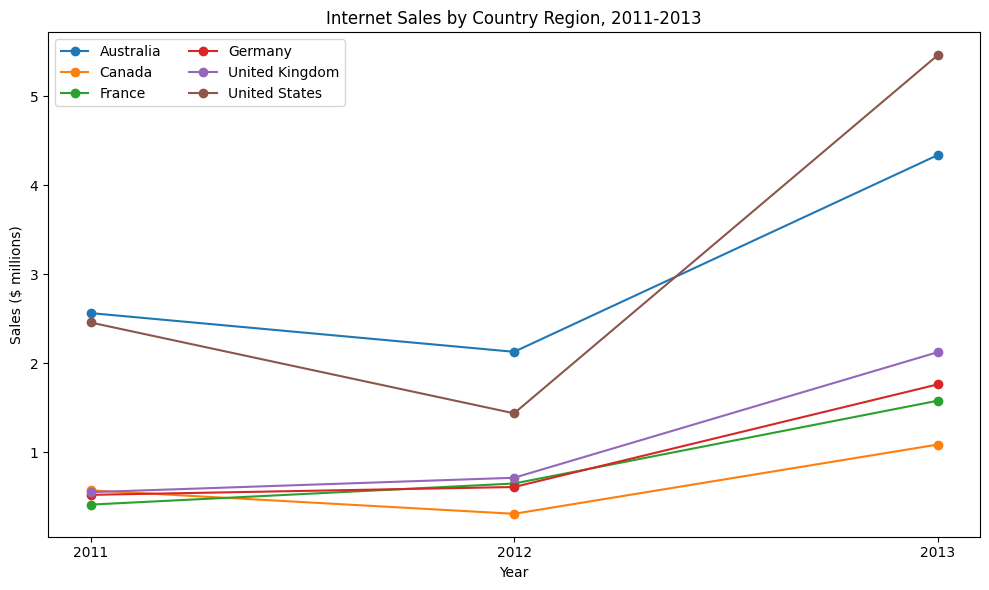

In [9]:
complete = year_country.loc[[2011, 2012, 2013]] / 1_000_000
fig, ax = plt.subplots(figsize=(10, 6))
for country in complete.columns:
    ax.plot(complete.index, complete[country], marker='o', label=country)
ax.set_title('Internet Sales by Country Region, 2011-2013')
ax.set_xlabel('Year')
ax.set_ylabel('Sales ($ millions)')
ax.set_xticks([2011, 2012, 2013])
ax.legend(ncol=2)
fig.tight_layout()
plt.show()

**Answer:** The United States and Australia are the two largest Internet sales markets in the full dataset. In 2013, U.S. sales reached about $5.46 million  and Australia reached about $4.34 million. France, Germany, and the United Kingdom also grew strongly between the complete years 2011 and 2013. The very low totals in 2010 and 2014 are caused by partial-year coverage, not a business collapse.

## Question 2. Summary Statistics for Yearly Income and Gender by Country Region

Customer attributes repeat across transactions, so this analysis first keeps one row per customer. `Gender` is categorical, so min, max, and standard deviation are not meaningful for it. Instead, the notebook reports counts and percentages for gender, while Yearly Income receives numeric summary statistics.

In [10]:
customers = sales[[
    'CustomerKey','EnglishCountryRegionName','Gender','YearlyIncome','HouseOwnerFlag'
]].drop_duplicates('CustomerKey')

income_summary = customers.groupby('EnglishCountryRegionName')['YearlyIncome'].agg(
    ['count','min','max','mean','median','std']
).round(2)
income_summary

,count,min,max,mean,median,std
EnglishCountryRegionName,,,,,,
Australia,3591,10000,170000,64338.62,70000.0,31830.00
Canada,1571,10000,170000,57167.41,60000.0,20251.52
France,1810,10000,110000,35762.43,30000.0,27277.40
Germany,1780,10000,130000,42943.82,30000.0,35493.58
United Kingdom,1913,10000,170000,52169.37,30000.0,48431.99
United States,7819,10000,170000,63616.83,60000.0,25706.48


In [11]:
gender_counts = pd.crosstab(customers['EnglishCountryRegionName'], customers['Gender'])
gender_percent = (pd.crosstab(
    customers['EnglishCountryRegionName'], customers['Gender'], normalize='index'
) * 100).round(1)

print('Gender counts')
display(gender_counts)
print('Gender percentages')
display(gender_percent)

Gender counts


Gender,F,M
EnglishCountryRegionName,,
Australia,1777,1814
Canada,767,804
France,893,917
Germany,874,906
United Kingdom,934,979
United States,3888,3931


Gender percentages


Gender,F,M
EnglishCountryRegionName,,
Australia,49.5,50.5
Canada,48.8,51.2
France,49.3,50.7
Germany,49.1,50.9
United Kingdom,48.8,51.2
United States,49.7,50.3


**Answer:** Australia and the United States have the highest mean Yearly Income in this customer base, at approximately $64.3K and $63.6K. France has the lowest mean, at approximately **$35.8K**. Gender composition is nearly balanced in every country region, with female shares between about 48.8% and 49.7%.

## Question 3. Average Price of the Product Category That Generates the Most Sales

In [12]:
category_summary = sales.groupby('ProductCategory').agg(
    TotalSales=('SalesAmount','sum'),
    Transactions=('SalesAmount','size'),
    AverageUnitPrice=('UnitPrice','mean'),
    MedianUnitPrice=('UnitPrice','median')
).sort_values('TotalSales', ascending=False)
category_summary['SalesSharePct'] = category_summary['TotalSales'] / category_summary['TotalSales'].sum() * 100
category_summary.round(2)

,TotalSales,Transactions,AverageUnitPrice,MedianUnitPrice,SalesSharePct
ProductCategory,,,,,
Bikes,28318144.65,15205,1862.42,2071.42,96.46
Accessories,700759.96,36092,19.42,9.99,2.39
Clothing,339772.61,9101,37.33,49.99,1.16


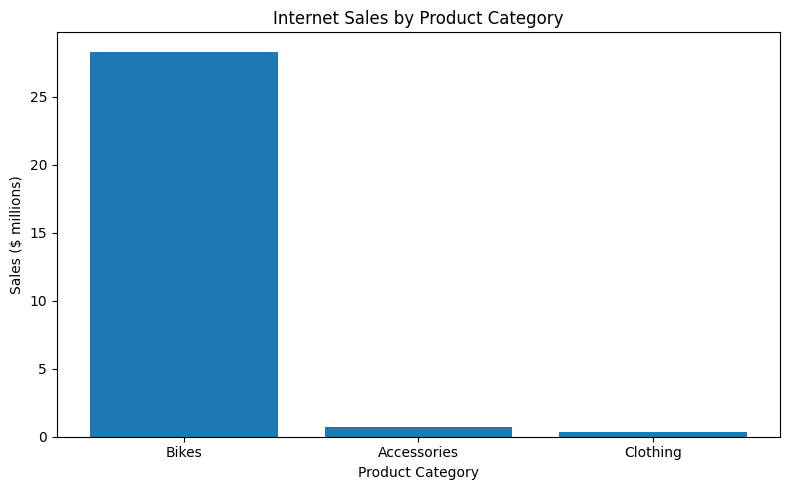

In [13]:
fig, ax = plt.subplots(figsize=(8,5))
plot_data = category_summary.reset_index()
ax.bar(plot_data['ProductCategory'], plot_data['TotalSales']/1_000_000)
ax.set_title('Internet Sales by Product Category')
ax.set_xlabel('Product Category')
ax.set_ylabel('Sales ($ millions)')
fig.tight_layout()
plt.show()

In [ ]:
Answer:Bikes generate the most Internet sales, with approximately $28.32 million, or about 96.46% of total sales. The transaction-weighted average observed unit price for Bikes is approximately $1,862.42.

## Question 4. Does Owning a Home Make a Difference in Sales?

To avoid counting frequent purchasers multiple times, sales are aggregated to the customer level before comparing homeowners and non-homeowners.

In [14]:
customer_sales = sales.groupby('CustomerKey').agg(
    TotalSales=('SalesAmount','sum'),
    Transactions=('SalesAmount','size'),
    AvgTransaction=('SalesAmount','mean')
).reset_index()

customer_analysis = customer_sales.merge(customers, on='CustomerKey', how='left')

home_summary = customer_analysis.groupby('HouseOwnerFlag').agg(
    Customers=('CustomerKey','count'),
    TotalSales=('TotalSales','sum'),
    MeanSalesPerCustomer=('TotalSales','mean'),
    MedianSalesPerCustomer=('TotalSales','median'),
    StdSalesPerCustomer=('TotalSales','std'),
    MeanTransactions=('Transactions','mean'),
    MeanIncome=('YearlyIncome','mean')
).round(2)
home_summary

,Customers,TotalSales,MeanSalesPerCustomer,MedianSalesPerCustomer,StdSalesPerCustomer,MeanTransactions,MeanIncome
HouseOwnerFlag,,,,,,,
0,5982,8973327.42,1500.05,209.96,2046.88,3.13,55172.18
1,12502,20385349.80,1630.57,342.00,2159.07,3.34,58326.67


Welch t-test p-value: 6.820263286221625e-05
Cohen d: 0.06146353140922165


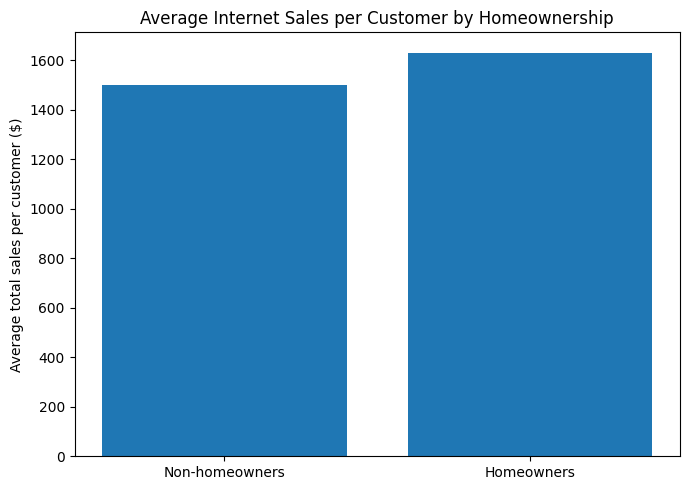

In [15]:
owners = customer_analysis.loc[customer_analysis['HouseOwnerFlag']==1, 'TotalSales']
nonowners = customer_analysis.loc[customer_analysis['HouseOwnerFlag']==0, 'TotalSales']
welch = stats.ttest_ind(owners, nonowners, equal_var=False)

# Cohen's d for practical effect size
n1, n0 = len(owners), len(nonowners)
s1, s0 = owners.std(ddof=1), nonowners.std(ddof=1)
sp = np.sqrt(((n1-1)*s1**2 + (n0-1)*s0**2) / (n1+n0-2))
d = (owners.mean() - nonowners.mean()) / sp

print('Welch t-test p-value:', welch.pvalue)
print('Cohen d:', d)

fig, ax = plt.subplots(figsize=(7,5))
ax.bar(['Non-homeowners','Homeowners'], [nonowners.mean(), owners.mean()])
ax.set_title('Average Internet Sales per Customer by Homeownership')
ax.set_ylabel('Average total sales per customer ($)')
fig.tight_layout()
plt.show()

**Answer:** Homeowners averaged about **$1,630.57** in total Internet sales per customer, compared with **$1,500.05** for non-homeowners, a difference of about **$130.52** or **8.7%**. The difference is statistically detectable in this large sample, but the standardized effect is very small (**Cohen's d ≈ 0.06**). Homeowners also have somewhat higher average income. Therefore, homeownership alone is not a strong practical basis for customer targeting, and this analysis does not establish a causal effect of owning a home on purchases.

## Leadership Recommendation

The strongest growth strategy is a **bike-led geographic and cross-selling strategy**. Bikes generate nearly all Internet sales, so leadership should protect this core category and focus marketing on the largest markets, especially the United States and Australia. At the same time, France, Germany, and the United Kingdom showed strong growth during 2011-2013 and provide evidence for continued international development.

Adventure Works should also use bike purchases as an opportunity to cross-sell Accessories and Clothing. These categories currently contribute only a small share of revenue, so bundles and post-purchase recommendations could increase order value without requiring the company to abandon its strongest product line. Homeownership should not be used as a primary targeting variable because its practical relationship with customer sales is small.

Because the dataset is fictitious and 2010/2014 are incomplete years, these recommendations are for learning purposes only.